In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:.3f}".format)

# ---- Load and merge LIHEAP, CalFresh and food bank ----
lagged_liheap = pd.read_csv("TimeLag_PolicyAnnotated.csv")
CalFresh = pd.read_csv("CalFresh_cleaned.csv").rename(columns={"Month Year": "Month_Year"})
FoodBank = pd.read_csv("FoodBank_cleaned.csv").rename(columns={"Month Year": "Month_Year"})

CalFresh_Merged = (CalFresh.groupby(["Zip Code", "Month_Year"], as_index=False)["Calfresh Dollars"].sum()
                   .rename(columns={"Calfresh Dollars": "CalFresh_Total_Dollars"}))
FoodBank_Merged = (FoodBank.groupby(["Zip Code", "Month_Year"], as_index=False)["Pounds_Distributed"].sum()
                   .rename(columns={"Pounds_Distributed": "FoodBank_Pounds_of_Food_Distributed"}))

fb = "FoodBank_Pounds_of_Food_Distributed"
FoodBank_Merged.loc[FoodBank_Merged[fb] == 0, fb] = np.nan

df = (lagged_liheap
      .merge(CalFresh_Merged, on=["Zip Code", "Month_Year"], how="left", validate="one_to_one")
      .merge(FoodBank_Merged, on=["Zip Code", "Month_Year"], how="left", validate="one_to_one")
      .rename(columns={"Enrollment_Count": "LIHEAP_Enrollment_Count"}))
assert len(df) == len(lagged_liheap)

# ---- Settings and helpers ----
LAGS = [0, 1, 2, 3]
LIHEAP_COLS = {0: "LIHEAP_Enrollment_Count", 1: "LIHEAP_lag1", 2: "LIHEAP_lag2", 3: "LIHEAP_lag3"}
OUTCOMES = {"CalFresh_Total_Dollars": "CalFresh",
            "FoodBank_Pounds_of_Food_Distributed": "Food bank"}
ALPHA = 0.05

def spearman_ci(rho, n, conf=0.95):
    """Fisher z interval for Spearman's rho (Bonett & Wright, 2000)."""
    z = np.arctanh(rho)
    se = np.sqrt((1 + rho**2 / 2) / (n - 3))
    zc = stats.norm.ppf(1 - (1 - conf) / 2)
    return np.tanh(z - zc * se), np.tanh(z + zc * se)

print("df ready:", df.shape)

df ready: (852, 38)


**Load In Segments Data**

In [16]:
seg = pd.read_csv("Zip_Segments.csv", dtype={"Zip_Code": str})
seg["Zip Code"] = seg["Zip_Code"].astype(int)
seg = seg.drop(columns=["Zip_Code"])

**Calcluate poverty_level urbanicity, housing_cost and single_mother_hh**

In [20]:
seg["Poverty_Level"] = pd.qcut(seg["Poverty_Rate_Pct"], 3, 
                               labels=["Low Poverty", "Medium Poverty", "High Poverty"])

seg["Urbanicity"] = pd.cut(seg["Density_per_sq_mi"], [0, 500, 3000, np.inf],
                           labels=["Rural", "Sururban", "Urban"], include_lowest=True)

seg["Housing_Cost"] = pd.qcut(seg["Median_Gross_Rent"], 3,
                             labels=["Low Rent", "Medium Rent", "High Rent"])

seg["Single_Mother_HH"] = pd.qcut(seg["Single_Mothers_per_1k"], 3,
                                 labels=["Few single-mother HH", "Some single-mother HH", "Many single-mother HH"])

SEGMENTS = {"Poverty_Level": "Poverty level",
           "Urbanicity": "Urban vs. suburban/rural",
           "Housing_Cost": "Housing cost",
           "Single_Mother_HH": "House composition"}

for col in ["Poverty_Rate_Pct", "Median_Gross_Rent", "Single_Mothers_per_1k"]:
    print(col, "tertile cutoffs:", seg[col].quantile([1/3, 2/3]).round(1).tolist())

dfs = df.merge(seg[["Zip Code"] + list(SEGMENTS)], on="Zip Code", how="left", validate="many_to_one")

for col, name in SEGMENTS.items():
    print(f"\n{name}:")
    print(seg[col].value_counts().sort_index().to_string())

Poverty_Rate_Pct tertile cutoffs: [8.0, 11.1]
Median_Gross_Rent tertile cutoffs: [1936.0, 2416.0]
Single_Mothers_per_1k tertile cutoffs: [12.6, 19.9]

Poverty level:
Poverty_Level
Low Poverty       33
Medium Poverty    33
High Poverty      33

Urban vs. suburban/rural:
Urbanicity
Rural       27
Sururban    26
Urban       50

Housing cost:
Housing_Cost
Low Rent       31
Medium Rent    30
High Rent      30

House composition:
Single_Mother_HH
Few single-mother HH     34
Some single-mother HH    33
Many single-mother HH    34


**Populate Correlations Within Each Segment**

In [25]:
LAG = 1 
x = LIHEAP_COLS[LAG]
MIN_N = 20

rows = []
for seg_col, seg_name in SEGMENTS.items():
    for level in dfs[seg_col].cat.categories:
        part = dfs[dfs[seg_col] == level]
        for out, label in OUTCOMES.items():
            sub = part[["Zip Code", x, out]].dropna()
            row = dict(Segment=seg_name, Group=level, Outcome=label,
                      n=len(sub), Zips=sub["Zip Code"].nunique())
            if len(sub) >= MIN_N and sub[x].nunique() > 1:
                p = stats.pearsonr(sub[x], sub[out])
                p_lo, p_hi = p.confidence_interval(confidence_level=1 - ALPHA)
                s = stats.spearmanr(sub[x], sub[out])
                s_lo, s_hi = spearman_ci(s.statistic, len(sub))
                row.update(Pearson_r=p.statistic, Pearson_CI_low=p_lo, Pearson_CI_high=p_hi, Pearson_p=p.pvalue,
                          Spearman_rho=s.statistic, Spearman_CI_low=s_lo, Spearman_CI_high=s_hi, Spearman_p=s.pvalue)
                rows.append(row)

seg_results = pd.DataFrame(rows)
seg_results

,Segment,Group,Outcome,n,Zips,Pearson_r,Pearson_CI_low,Pearson_CI_high,Pearson_p,Spearman_rho,Spearman_CI_low,Spearman_CI_high,Spearman_p
0,Poverty level,Low Poverty,CalFresh,161,29,0.419,0.282,0.539,0.000,0.543,0.414,0.650,0.000
1,Poverty level,Low Poverty,Food bank,147,25,0.050,-0.112,0.211,0.545,-0.020,-0.181,0.142,0.809
2,Poverty level,Medium Poverty,CalFresh,197,31,0.381,0.255,0.494,0.000,0.561,0.448,0.656,0.000
3,Poverty level,Medium Poverty,Food bank,197,31,0.325,0.194,0.444,0.000,0.474,0.352,0.581,0.000
4,Poverty level,High Poverty,CalFresh,168,29,0.553,0.438,0.650,0.000,0.638,0.528,0.727,0.000
5,Poverty level,High Poverty,Food bank,158,27,0.278,0.128,0.416,0.000,0.522,0.389,0.633,0.000
6,Urban vs. suburban/rural,Rural,CalFresh,55,17,0.506,0.278,0.680,0.000,0.675,0.476,0.808,0.000
7,Urban vs. suburban/rural,Rural,Food bank,53,16,0.435,0.186,0.631,0.001,0.627,0.408,0.778,0.000
8,Urban vs. suburban/rural,Sururban,CalFresh,159,25,0.643,0.542,0.726,0.000,0.695,0.593,0.775,0.000
9,Urban vs. suburban/rural,Sururban,Food bank,148,23,0.627,0.518,0.716,0.000,0.532,0.396,0.645,0.000


**Step 4: Compare Correlation Strength Across Segments**

In [29]:
def compare_corr(r1, n1, r2, n2, spearman=True):
    """Two-sided test that two independent correlations differ (Fisher z)."""
    k = 1.06 if spearman else 1.0
    z = (np.arctanh(r1) - np.arctanh(r2)) / np.sqrt(k / (n1 - 3) + k / (n2 - 3))
    return 2 * stats.norm.sf(abs(z))

comp = []
for (seg_name, label), g in seg_results.dropna(subset=["Spearman_rho"]).groupby(["Segment", "Outcome"], sort=False):
    top = g.loc[g["Spearman_rho"].idxmax()]
    low = g.loc[g["Spearman_rho"].idxmin()]
    comp.append(dict(Segment=seg_name, Outcome=label,
                    Strongest=top["Group"], Strongest_rho=["Spearman_rho"], Strongest_n=top["n"],
                    Weakest=low["Group"], Weakest_rho=low["Spearman_rho"], Weakest_n=low["n"],
                    Difference=top["Spearman_rho"] - low["Spearman_rho"],
                    p_difference=compare_corr(top["Spearman_rho"], top["n"], low["Spearman_rho"], low["n"])))

comparison = pd.DataFrame(comp)
comparison["Significant"] = np.where(comparison["p_difference"] < 0.05, "Yes", "No")
comparison

,Segment,Outcome,Strongest,Strongest_rho,Strongest_n,Weakest,Weakest_rho,Weakest_n,Difference,p_difference,Significant
0,Poverty level,CalFresh,High Poverty,[Spearman_rho],168,Low Poverty,0.543,161,0.096,0.199,No
1,Poverty level,Food bank,High Poverty,[Spearman_rho],158,Low Poverty,-0.020,147,0.542,0.000,Yes
2,Urban vs. suburban/rural,CalFresh,Sururban,[Spearman_rho],159,Urban,0.452,312,0.243,0.000,Yes
3,Urban vs. suburban/rural,Food bank,Rural,[Spearman_rho],53,Urban,0.345,301,0.282,0.017,Yes
4,Housing cost,CalFresh,Medium Rent,[Spearman_rho],174,Low Rent,0.461,187,0.192,0.010,Yes
5,Housing cost,Food bank,Medium Rent,[Spearman_rho],174,High Rent,0.136,137,0.299,0.006,Yes
6,House composition,CalFresh,Few single-mother HH,[Spearman_rho],140,Many single-mother HH,0.453,197,0.177,0.027,Yes
7,House composition,Food bank,Many single-mother HH,[Spearman_rho],197,Some single-mother HH,0.258,180,0.187,0.045,Yes


**Step 5: Plot the segments side by side**

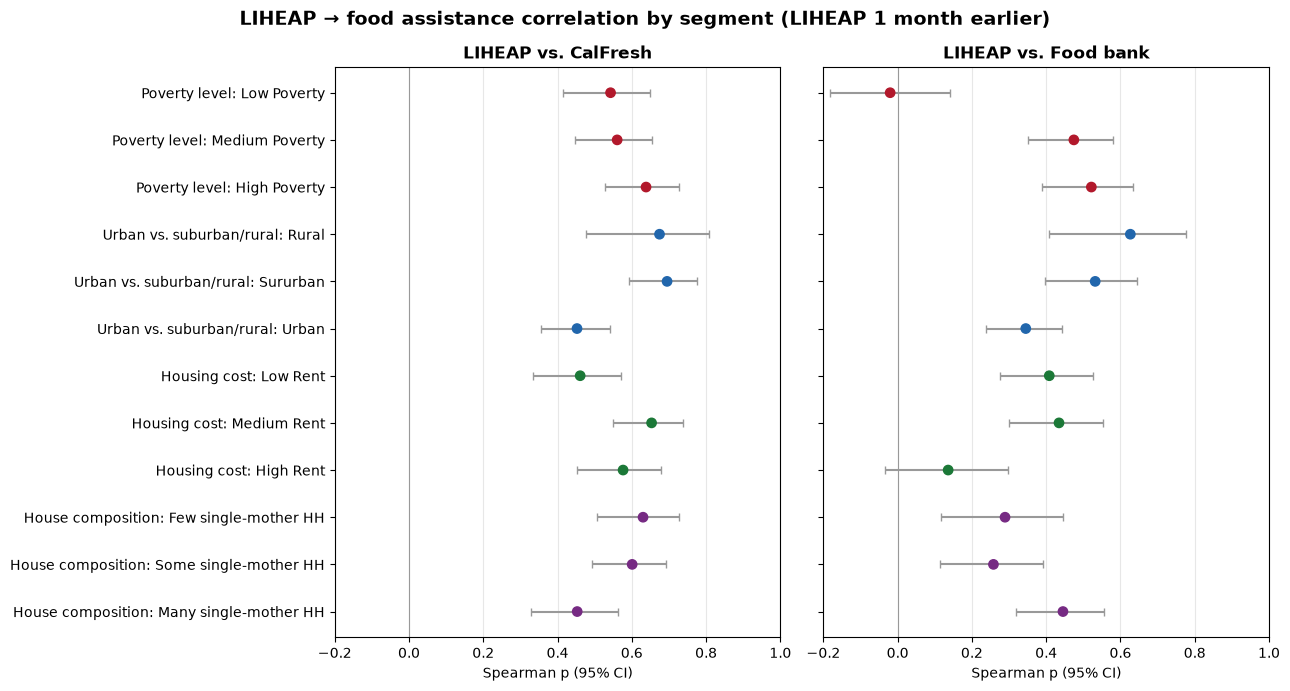

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)

plot = seg_results.dropna(subset=["Spearman_rho"]).copy()
plot["Label"] = plot["Segment"] + ": " + plot["Group"].astype(str)
order = plot.drop_duplicates("Label")["Label"].tolist()[::-1]
seg_colors = dict(zip(SEGMENTS.values(), ["#b2182b", "#2166ac", "#1b7837", "#762a83"]))

for ax, (label, g) in zip(axes, plot.groupby("Outcome", sort=False)):
    g = g.set_index("Label").reindex(order).dropna(subset=["Spearman_rho"])
    ys = [order.index(l) for l in g.index]
    ax.errorbar(g["Spearman_rho"], ys,
                xerr=[g["Spearman_rho"] - g["Spearman_CI_low"], g["Spearman_CI_high"] - g["Spearman_rho"]],
                fmt="none", ecolor="#999", capsize=3)
    ax.scatter(g["Spearman_rho"], ys, c=[seg_colors[s] for s in g["Segment"]], s=45, zorder=3)
    ax.set_title(f"LIHEAP vs. {label}", fontweight="bold")
    ax.set_xlim(-0.2, 1)
    ax.axvline(0, color="#999", lw=0.8)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlabel("Spearman p (95% CI)")

axes[0].set_yticks(range(len(order)), order)
fig.suptitle(f"LIHEAP → food assistance correlation by segment (LIHEAP {LAG} month earlier)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("Segment_Correlations.png", dpi=300, bbox_inches="tight")
plt.show()

## Summary of Findings

The link between LIHEAP enrollment and food assistance is not uniform across San Diego County: it is strongest in suburban, rural and higher-poverty zip codes and weakest in urban and affluent ones. This matters most for food bank distribution, where the relationship ranges from none at all in low-poverty zip codes to moderate in high-poverty zip codes.

**What we did:** Zip codes were divided by poverty level, urban vs. suburban/rural density, housing cost (median rent) and household composition (single-mother households). Within each segment, LIHEAP enrollment one month earlier was correlated with CalFresh dollars and food bank pounds using Spearman correlations with 95% confidence intervals.

**Key results:**
- **CalFresh:** LIHEAP and CalFresh moved together in every segment (ρ ≈ 0.45–0.69). The relationship was strongest in suburban zip codes (ρ ≈ 0.69) and weakest in urban zip codes (ρ ≈ 0.45).
- **Food bank:** The relationship depended heavily on the segment. It was moderate in rural, suburban and higher-poverty zip codes (ρ ≈ 0.47–0.63), weak in high-rent zip codes (ρ ≈ 0.13) and absent in low-poverty zip codes (ρ ≈ −0.02).
- **Urban zip codes** showed the weakest signal for both programs, likely because food bank sites and services there draw residents from across zip code lines.

**Why it matters:** LIHEAP enrollment is a useful indicator of food assistance need in suburban, rural and higher-poverty areas, where the programs reach the same households. In urban and affluent areas, LIHEAP enrollment is a weaker guide to food assistance need, and program planning there should rely on direct measures of food insecurity.

**Caveats:** Segments contain about a third of zip codes each (fewer for rural), the segment variables overlap with one another, and observations are repeated monthly within zip codes. Differences between segments should be treated as significant only where the Fisher z-test confirms them (p < 0.05). 